# Paris air-quality forecasting

A 504-hour, five-pollutant forecast with two naïve baselines, a dataset-trained LSTM, and independent/joint zero-shot Chronos-2. All model inputs stop at the forecast origin. The validation period and scoring code are shared across methods.

**Run in Google Colab with a GPU:** select Runtime → Change runtime type → GPU, then run all cells. Upload the three competition CSVs when prompted. Local execution from this repository works too.

In [1]:
import os
import subprocess
import sys
import zipfile
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not Path('paris-air-quality-forecasting').exists():
        subprocess.run(['git', 'clone', '--branch', 'assignment-forecasting', 'https://github.com/RyanBalech/paris-air-quality-forecasting.git'], check=True)
    os.chdir('paris-air-quality-forecasting')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', '.[assignment]'], check=True)
    from google.colab import files
    Path('data/raw').mkdir(parents=True, exist_ok=True)
    if not Path('data/raw/competition.zip').exists():
        print('Upload train.csv, test.csv and sample_submission.csv, or competition.zip')
        uploaded = files.upload()
        if 'competition.zip' in uploaded:
            Path('data/raw/competition.zip').write_bytes(uploaded['competition.zip'])
        else:
            with zipfile.ZipFile('data/raw/competition.zip', 'w') as archive:
                for name in ('train.csv', 'test.csv', 'sample_submission.csv'):
                    archive.writestr(name, uploaded[name])
print('Working directory:', Path.cwd().name)


Working directory: paris-air-quality-forecasting


## 1. Data understanding

The `id` strings encode consecutive hourly timestamps. The loader rejects unsorted or duplicate timestamps. Descriptive plots use only pre-validation observations, so they cannot guide modelling with held-out values. A random split would mix past and future hours and overstate forecasting accuracy.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from paris_air_quality.assignment import split_validation
from paris_air_quality.data import TARGETS, load_competition

train, test, sample = load_competition()
history, actual = split_validation(train)
print('Train:', train.index[0], 'through', train.index[-1], len(train), 'rows')
print('Test:', test.index[0], 'through', test.index[-1], len(test), 'rows')
print('Validation:', actual.index[0], 'through', actual.index[-1])
display(history.describe(percentiles=[.01, .5, .99]).T)
display(pd.DataFrame({'missing': history.isna().sum(), 'missing_pct': 100 * history.isna().mean()}))
display(history.corr())


Train: 2020-01-01 00:00:00 through 2024-09-03 22:00:00 40991 rows
Test: 2024-09-03 23:00:00 through 2024-09-24 22:00:00 504 rows
Validation: 2024-08-13 23:00:00 through 2024-09-03 22:00:00


,count,mean,std,min,1%,50%,99%,max
valeur_NO2,37300.0,21.950024,14.666742,1.100,4.500,17.700,71.500,131.000
valeur_CO,27964.0,0.201214,0.104358,0.037,0.088,0.177,0.587,4.309
valeur_O3,39794.0,50.548341,26.562522,-1.900,0.700,50.700,123.400,193.100
valeur_PM10,33525.0,18.251031,11.311925,0.500,3.200,15.600,59.300,128.500
valeur_PM25,38709.0,11.083603,8.183097,0.000,1.700,8.700,41.300,111.100


,missing,missing_pct
valeur_NO2,3187,7.871663
valeur_CO,12523,30.930916
valeur_O3,693,1.711661
valeur_PM10,6962,17.195643
valeur_PM25,1778,4.391533


,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
valeur_NO2,1.000000,0.707085,-0.644028,0.509781,0.520347
valeur_CO,0.707085,1.000000,-0.485173,0.531091,0.626502
valeur_O3,-0.644028,-0.485173,1.000000,-0.209701,-0.298351
valeur_PM10,0.509781,0.531091,-0.209701,1.000000,0.887764
valeur_PM25,0.520347,0.626502,-0.298351,0.887764,1.000000


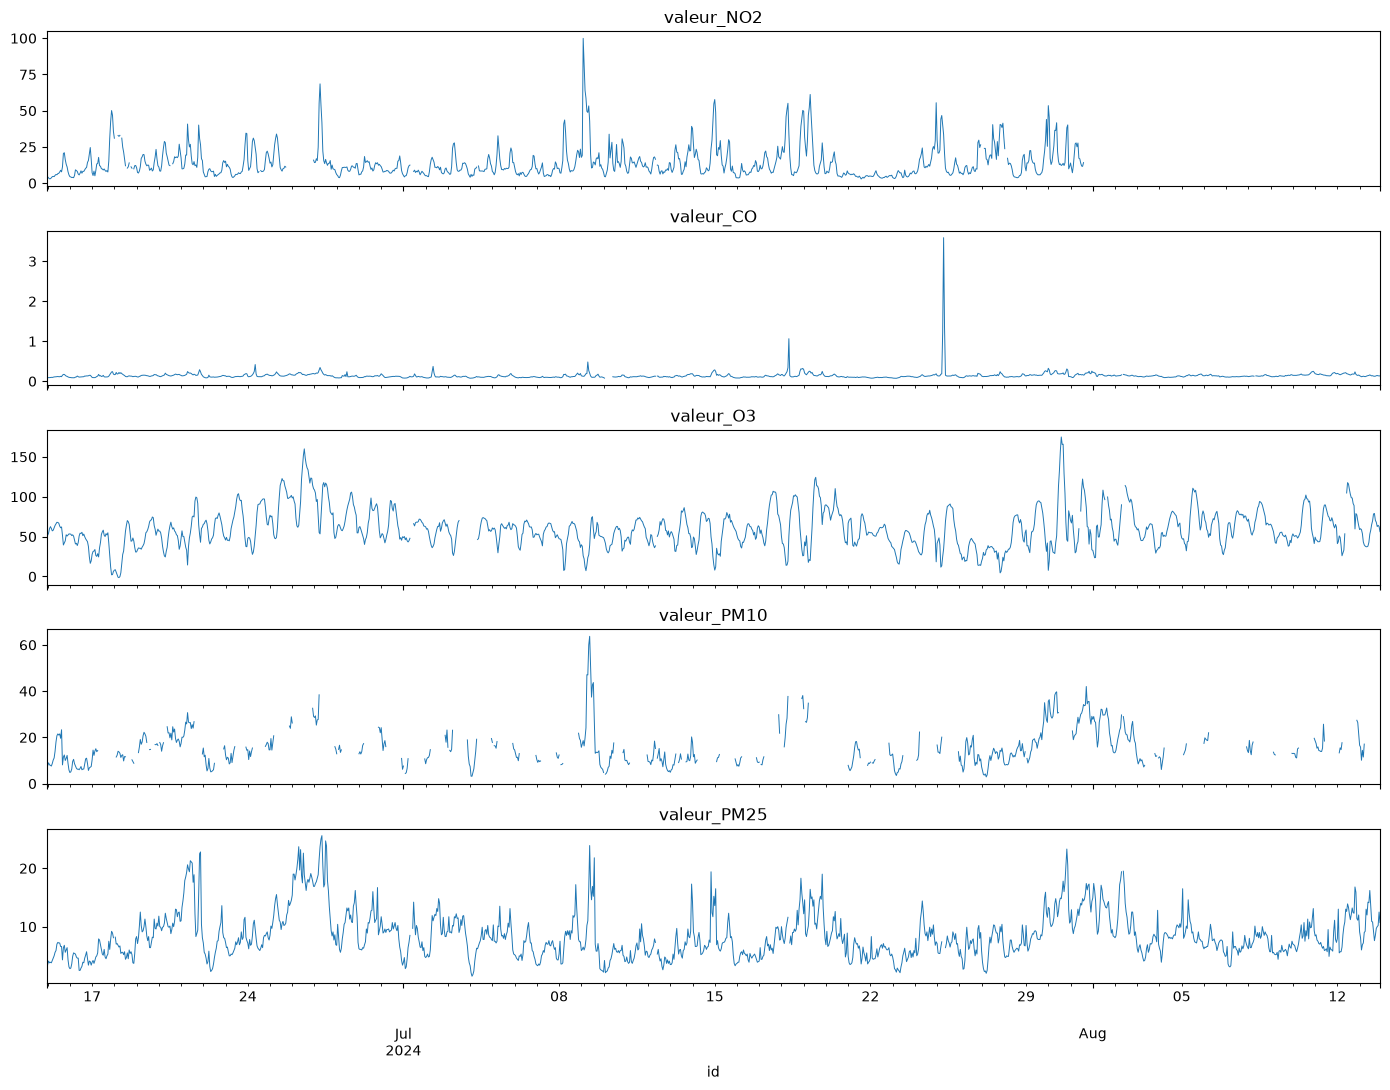

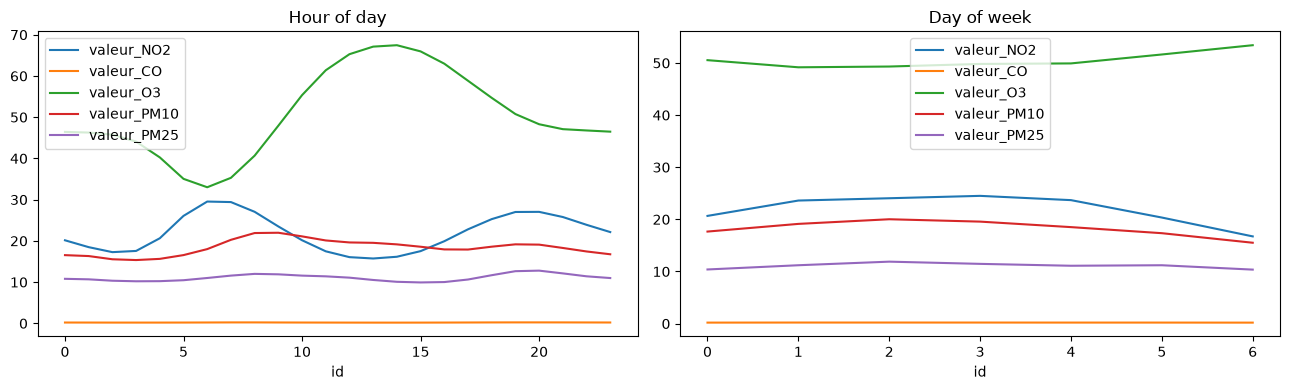

In [3]:
fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
for ax, target in zip(axes, TARGETS):
    history[target].iloc[-24*60:].plot(ax=ax, lw=.7, title=target)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
history.groupby(history.index.hour).mean().plot(ax=axes[0], title='Hour of day')
history.groupby(history.index.dayofweek).mean().plot(ax=axes[1], title='Day of week')
plt.tight_layout(); plt.show()


## 2. Forecast protocol and baselines

The final 504 training hours are held out. Persistence repeats the last available values. Seasonal naïve repeats the last 168 hours, preserving weekday and hour over the 21-day horizon. Input gaps are filled with pre-cutoff forward fill and historical medians; there is no interpolation from validation or test labels. MAE is computed separately for each pollutant and then averaged equally.

In [4]:
from paris_air_quality.assignment import persistence, score, seasonal_naive

baselines = {'persistence': persistence(history, actual.index), 'seasonal_naive_168h': seasonal_naive(history, actual.index)}
for name, prediction in baselines.items():
    print(name, score(actual, prediction))


persistence {'score': 6.698695194287649, 'per_target': {'valeur_NO2': 7.428680203045685, 'valeur_CO': 0.04580722891566265, 'valeur_O3': 16.159920634920635, 'valeur_PM10': 5.622408026755854, 'valeur_PM25': 4.236659877800407}, 'observed_rows': {'valeur_NO2': 394, 'valeur_CO': 498, 'valeur_O3': 504, 'valeur_PM10': 299, 'valeur_PM25': 491}, 'week_mae': {'1': {'score': 6.334612934447955, 'per_target': {'valeur_NO2': 6.614935064935065, 'valeur_CO': 0.025820987654320986, 'valeur_O3': 14.373214285714287, 'valeur_PM10': 6.2227848101265835, 'valeur_PM25': 4.436309523809523}, 'observed_rows': {'valeur_NO2': 154, 'valeur_CO': 162, 'valeur_O3': 168, 'valeur_PM10': 79, 'valeur_PM25': 168}}, '2': {'score': 6.9689828775945655, 'per_target': {'valeur_NO2': 8.338620689655173, 'valeur_CO': 0.04004761904761905, 'valeur_O3': 17.336904761904766, 'valeur_PM10': 5.0, 'valeur_PM25': 4.129341317365269}, 'observed_rows': {'valeur_NO2': 145, 'valeur_CO': 168, 'valeur_O3': 168, 'valeur_PM10': 93, 'valeur_PM25': 16

## 3. Zero-shot and LSTM comparisons

Chronos-2 uses a fixed pretrained checkpoint and a 2,048-hour context. The independent call treats pollutants as separate series; the joint call forecasts all five together. We use its median quantile because absolute error is minimized by a conditional median. The small joint LSTM is fit only on pre-cutoff pollutant history, then rolls 24-hour blocks to 504 hours. No future weather observations enter any method.

In [5]:
import chronos
import torch

from paris_air_quality.assignment import run

print('PyTorch:', torch.__version__, 'Chronos:', getattr(chronos, '__version__', 'unknown'), 'GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
result = run()
display(pd.DataFrame({name: {'Mean MAE': values['validation']['score'], **values['validation']['per_target']} for name, values in result['methods'].items()}).T.sort_values('Mean MAE'))
print('Selected by validation:', result['selected_method'])


PyTorch: 2.14.1+cu130 Chronos: 2.3.2 GPU: NVIDIA GeForce RTX 4050 Laptop GPU


,Mean MAE,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
chronos2_independent,5.700990,7.205601,0.046291,12.970213,5.054454,3.228393
chronos2_joint,5.854188,7.450750,0.040601,13.105554,5.314983,3.359051
lstm_joint,6.503962,7.699952,0.031502,16.347863,5.158406,3.282089
persistence,6.698695,7.428680,0.045807,16.159921,5.622408,4.236660
seasonal_naive_168h,6.872438,7.428680,0.044494,17.289881,6.044147,3.554990


Selected by validation: chronos2_independent


## 4. Horizon and error analysis

The table compares three 168-hour subperiods; the plot compares observations with seasonal naïve and the selected method. A model can win the average and still lose for a pollutant or later week.

,week_1,week_2,week_3
persistence,6.334613,6.968983,6.808138
seasonal_naive_168h,6.565898,6.704128,7.305074
lstm_joint,5.711546,6.317703,7.297568
chronos2_independent,5.326337,5.449404,6.269892
chronos2_joint,5.374847,5.796662,6.353887


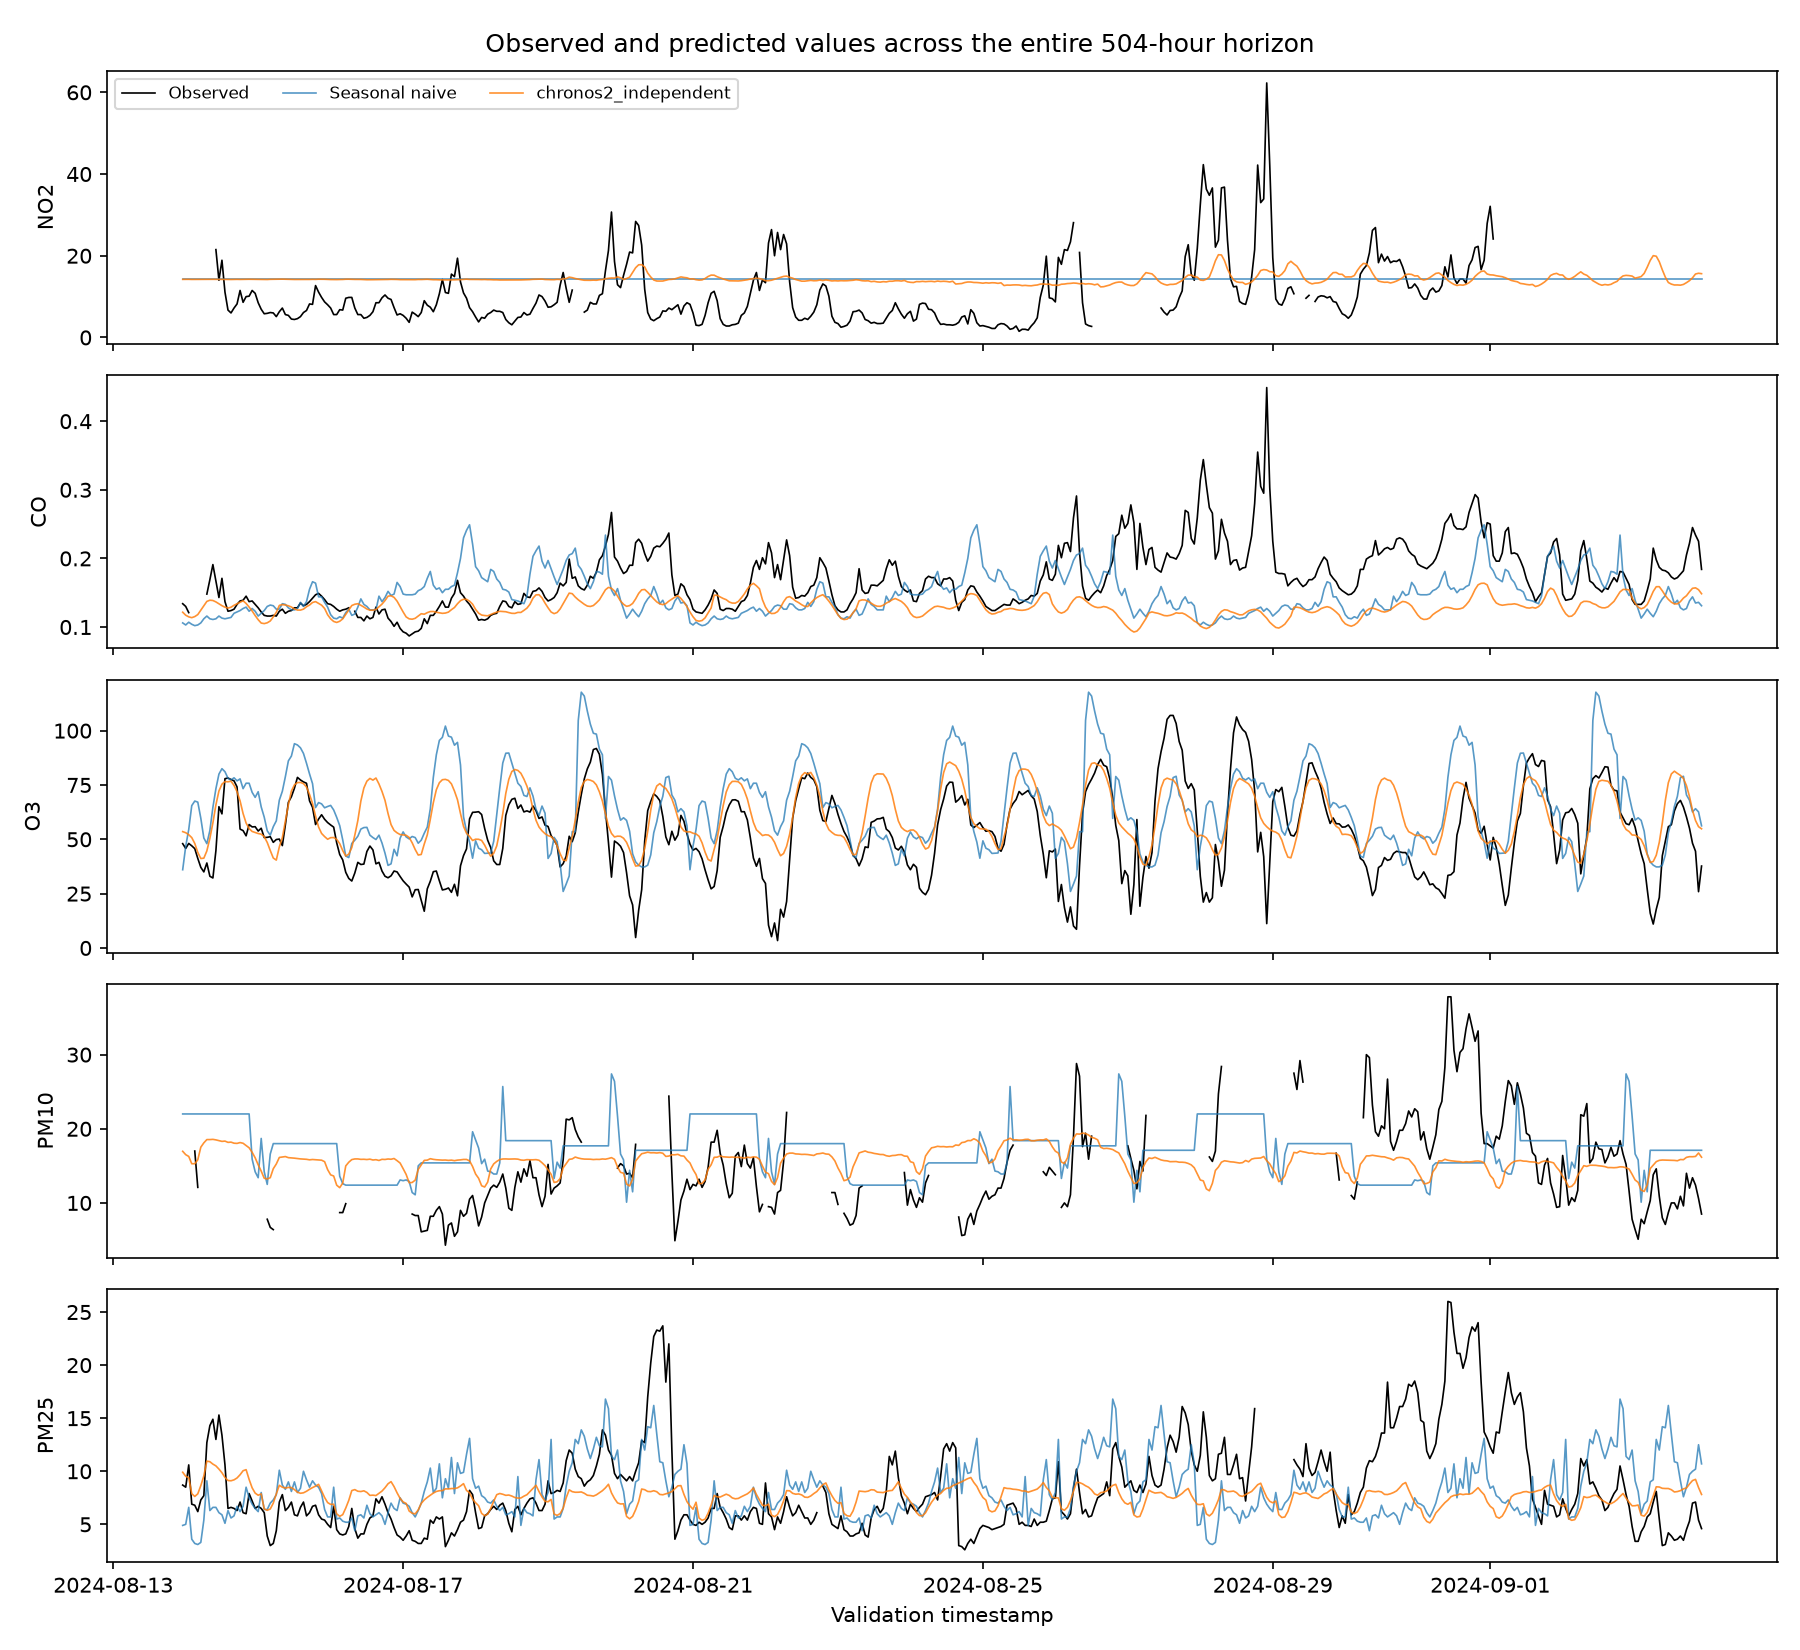

Full written report: docs\assignment\report.md


In [6]:
from paris_air_quality.assignment_report import create_report

report_path = create_report()
week = {name: {f'week_{k}': v['score'] for k, v in values['validation']['week_mae'].items()} for name, values in result['methods'].items()}
display(pd.DataFrame(week).T)
from IPython.display import Image, display

display(Image(filename='docs/assignment/figures/observed_vs_predicted.png'))
print('Full written report:', report_path)


## 5. Final forecast

The best method by validation mean MAE is refit or rerun using all observed training history. Export preserves sample ID order, column names, and 504 complete rows. The assignment forecast is separate from the weather-enabled Kaggle study.

In [7]:
submission = pd.read_csv('outputs/assignment/assignment_submission.csv')
assert submission.columns.tolist() == sample.columns.tolist()
assert submission.id.equals(sample.id) and len(submission) == 504
assert submission[list(TARGETS)].notna().all().all()
display(submission.head())
if IN_COLAB:
    files.download('outputs/assignment/assignment_submission.csv')


,id,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
0,2024-09-03 23,23.862431,0.169231,42.454571,8.395616,4.697104
1,2024-09-04 00,23.904076,0.160339,41.898556,8.548321,4.907578
2,2024-09-04 01,23.928732,0.155140,41.196232,8.370763,5.393844
3,2024-09-04 02,23.800318,0.153537,39.762840,7.988276,4.459914
4,2024-09-04 03,23.738024,0.156469,36.809380,7.962334,4.293938


## References and covariates

Pollutant history is the target history; historical weather is a past-only covariate; hour of day is known in advance. Future *observed* weather is not known at the forecast origin and is excluded. See the generated short report for limitations and pollutant-specific findings.

- [Ansari et al., Chronos-2](https://arxiv.org/abs/2510.15821)
- [Amazon Science Chronos quick start](https://github.com/amazon-science/chronos-forecasting)
- [Kaggle challenge](https://www.kaggle.com/competitions/x-hec-ts-2025-predicting-air-quality-in-paris/overview)